# 02. 탐색적 분석 (EDA)

약한 라벨 규칙(제목에 종목명 포함 + 같은 URL 병합·태그 합집합)을 적용한 D2와 D3 원본을 살펴보고,
모델링 전에 확인할 가설을 세운다.

**가설**
1. 태그 간 기사 수 불균형이 크다 → `class_weight`, 태그별 임계값, 태그별 상한(cap)이 필요하다.
2. 산업 사슬로 연결된 태그는 같이 보도된다 (2차전지·자동차, 원전·전력기기 ↔ 건설 등).
3. 종목 기사(D2)와 일반 경제 기사(D3)는 어휘가 다르다 → 약한 라벨 검증 점수보다 골드셋 점수가 낮을 것이다.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from src.config import RAW, OUTPUTS, TAGS
from src.dataset import build_weak_labels, label_matrix
from src import viz
viz.setup()

d2_raw = pd.read_csv(RAW / "d2_stock_news_raw.csv", dtype={"code": str})
d3_raw = pd.read_csv(RAW / "d3_general_news_raw.csv")
weak = build_weak_labels(d2_raw, title_filter=True)
weak_nofilter = build_weak_labels(d2_raw, title_filter=False)
Y = label_matrix(weak.tag_list)
print(f"D2 원본 {len(d2_raw):,}행 → 제목 필터+URL 병합 {len(weak):,}건 (필터 없이 병합만: {len(weak_nofilter):,}건)")
print("결측치:\n", weak[["title", "description", "press", "pub_date"]].isna().sum().to_string())

D2 원본 419,512행 → 제목 필터+URL 병합 161,656건 (필터 없이 병합만: 259,608건)
결측치:
 title           0
description    54
press           0
pub_date        0


## 1. 태그별 기사 수 (불균형)

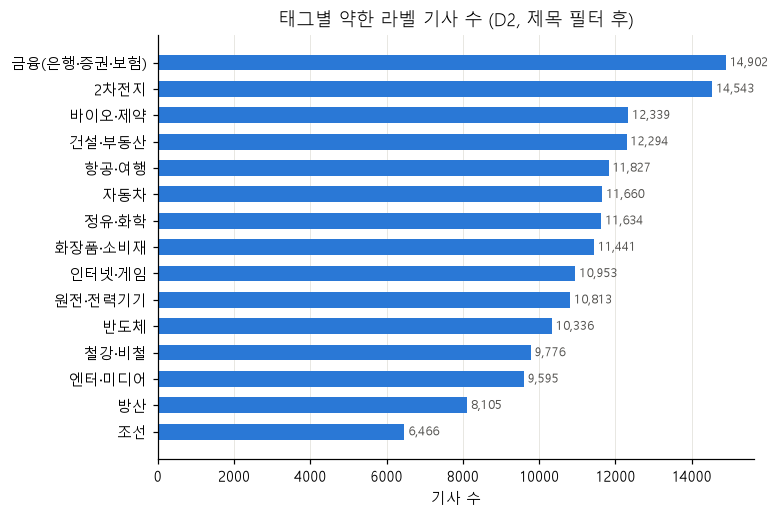

최다/최소 비율: 2.3배


In [2]:
cnt = pd.Series(Y.sum(0), index=TAGS).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(cnt.index, cnt.values, color=viz.BLUE, height=0.6)
for y, v in enumerate(cnt.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8, color="#52514e")
ax.set_title("태그별 약한 라벨 기사 수 (D2, 제목 필터 후)")
ax.set_xlabel("기사 수"); ax.grid(axis="y", visible=False)
viz.save(fig, "eda_tag_counts"); plt.show()
print(f"최다/최소 비율: {cnt.max() / cnt.min():.1f}배")

## 2. 다중 라벨 정도, 기사 길이, 언론사

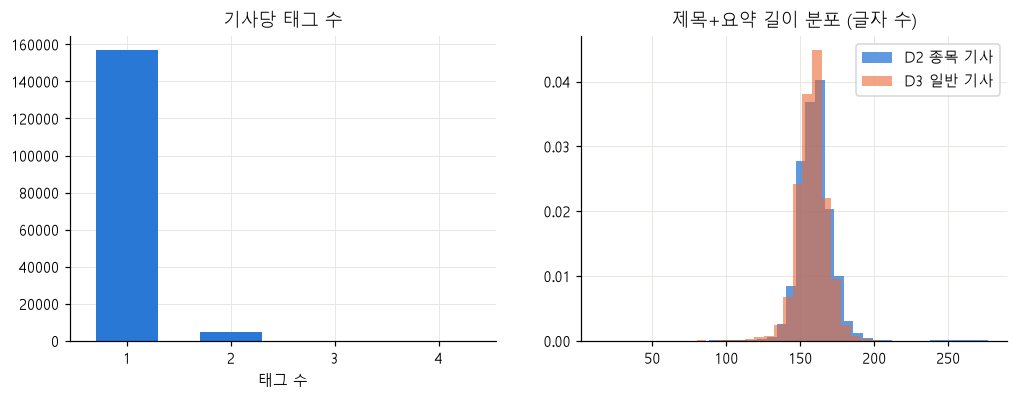

count    161656.0
mean        160.0
std          13.0
min          17.0
25%         153.0
50%         159.0
75%         166.0
max         277.0


In [3]:
weak["text_len"] = (weak.title.fillna("") + " " + weak.description.fillna("")).str.len()
d3_raw["text_len"] = (d3_raw.title.fillna("") + " " + d3_raw.description.fillna("")).str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
weak.n_tags.value_counts().sort_index().plot.bar(ax=axes[0], color=viz.BLUE, width=0.6)
axes[0].set_title("기사당 태그 수"); axes[0].set_xlabel("태그 수"); axes[0].tick_params(axis="x", rotation=0)
axes[1].hist(weak.text_len, bins=40, color=viz.BLUE, alpha=0.75, label="D2 종목 기사", density=True)
axes[1].hist(d3_raw.text_len, bins=40, color=viz.ORANGE, alpha=0.6, label="D3 일반 기사", density=True)
axes[1].set_title("제목+요약 길이 분포 (글자 수)"); axes[1].legend()
viz.save(fig, "eda_ntags_length"); plt.show()
print(weak.text_len.describe().round(0).to_string())

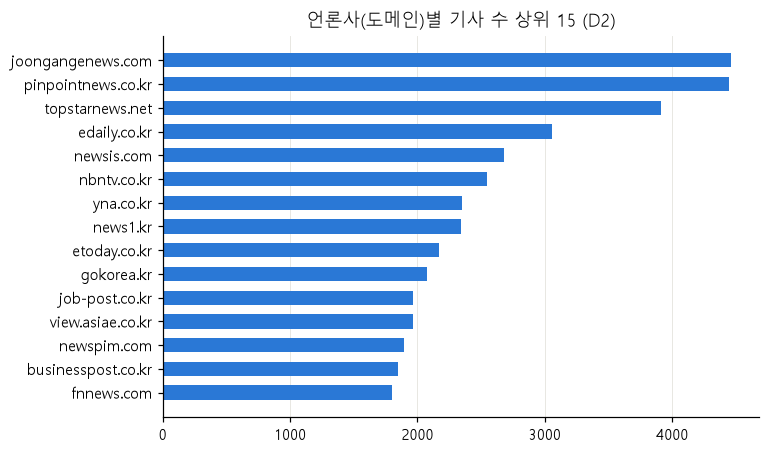

상위 15개 언론사 비중: 24.4%


In [4]:
top_press = weak.press.value_counts().head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_press.index[::-1], top_press.values[::-1], color=viz.BLUE, height=0.6)
ax.set_title("언론사(도메인)별 기사 수 상위 15 (D2)"); ax.grid(axis="y", visible=False)
viz.save(fig, "eda_press"); plt.show()
print(f"상위 15개 언론사 비중: {top_press.sum() / len(weak):.1%}")

## 3. 태그 동시 출현
한 기사에 두 태그가 같이 붙는 경우는 (a) 두 태그에 속한 종목(풍산, POSCO홀딩스, SK이노베이션) 또는
(b) 한 기사가 여러 대표 종목을 제목에 언급한 경우다. (b)가 '어떤 산업이 같이 보도되는가'를 보여준다.

In [5]:
co_all = pd.DataFrame(Y.T @ Y, index=TAGS, columns=TAGS)
weak["n_stocks"] = weak.stocks.str.count(r"\|") + 1
print("다중 태그 기사 중 '종목 1개'(=두 태그 종목) 비율:",
      f"{((weak.n_tags > 1) & (weak.n_stocks == 1)).sum() / (weak.n_tags > 1).sum():.1%}")
pd.Series({"2차전지·철강 (POSCO홀딩스 등)": co_all.loc["2차전지", "철강·비철"],
           "2차전지·정유화학 (SK이노베이션 등)": co_all.loc["2차전지", "정유·화학"],
           "철강·방산 (풍산 등)": co_all.loc["철강·비철", "방산"]}, name="전체 동시 출현 수").to_frame()

다중 태그 기사 중 '종목 1개'(=두 태그 종목) 비율: 77.9%


,전체 동시 출현 수
2차전지·철강 (POSCO홀딩스 등),1986
2차전지·정유화학 (SK이노베이션 등),1329
철강·방산 (풍산 등),869


위 세 쌍은 두 태그를 받은 종목 때문에 **구조적으로** 생긴다. '어떤 산업이 같이 보도되는가'를 보려면
서로 다른 대표 종목이 2개 이상 제목에 나온 기사만으로 동시 출현을 다시 센다.

종목 2개 이상 언급 기사: 3,731건


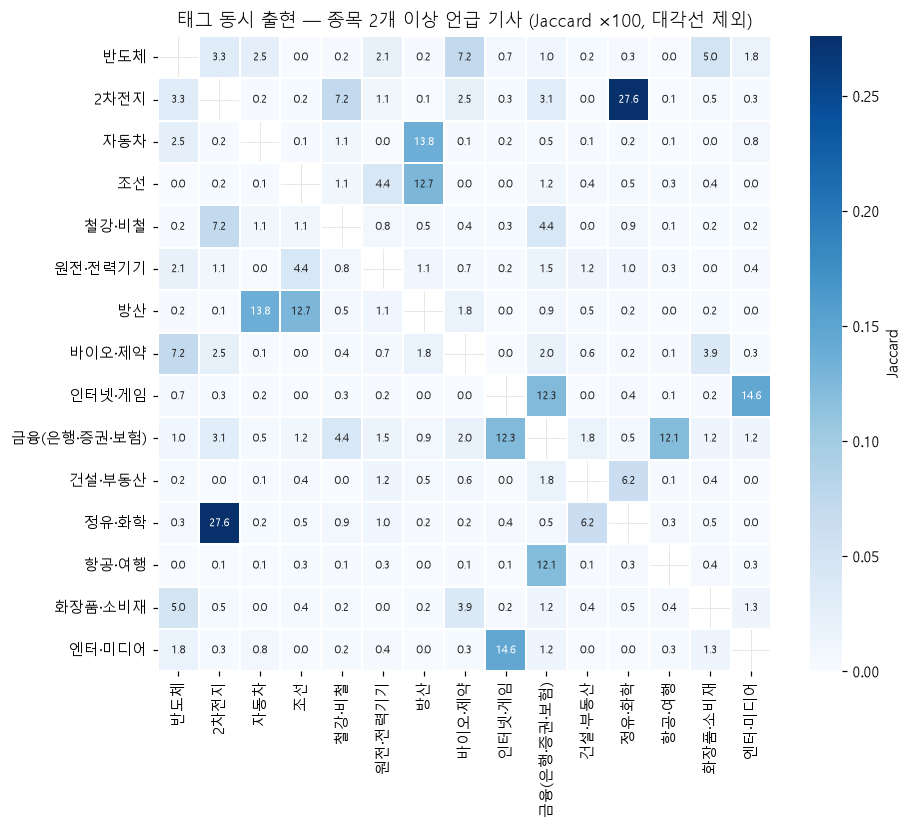

,태그1,태그2,jaccard,동시 기사 수
0,2차전지,정유·화학,0.275941,242
1,인터넷·게임,엔터·미디어,0.145794,78
2,자동차,방산,0.137532,107
3,조선,방산,0.126935,41
4,인터넷·게임,금융(은행·증권·보험),0.122940,97
5,금융(은행·증권·보험),항공·여행,0.121148,114
6,2차전지,철강·비철,0.071984,74
7,반도체,바이오·제약,0.071759,31


In [6]:
Ym = label_matrix(weak[weak.n_stocks >= 2].tag_list)
print(f"종목 2개 이상 언급 기사: {len(Ym):,}건")
co = pd.DataFrame(Ym.T @ Ym, index=TAGS, columns=TAGS)
# 대각선(자기 자신)을 빼고, 태그 크기 차이를 보정한 Jaccard 지수로 본다
inter = co.values.astype(float)
diag = np.diag(inter)
jac = inter / (diag[:, None] + diag[None, :] - inter)
np.fill_diagonal(jac, np.nan)
jac = pd.DataFrame(jac, index=TAGS, columns=TAGS)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(jac, cmap=viz.SEQ, ax=ax, annot=(jac * 100).round(1), fmt="", annot_kws={"size": 7},
            cbar_kws={"label": "Jaccard"}, linewidths=1, linecolor="white")
ax.set_title("태그 동시 출현 — 종목 2개 이상 언급 기사 (Jaccard ×100, 대각선 제외)")
viz.save(fig, "eda_cooccurrence"); plt.show()

pairs = (jac.where(np.triu(np.ones(jac.shape, bool), 1)).stack().sort_values(ascending=False)
         .head(8).rename("jaccard").reset_index())
pairs.columns = ["태그1", "태그2", "jaccard"]
pairs["동시 기사 수"] = [co.loc[a, b] for a, b in zip(pairs.태그1, pairs.태그2)]
pairs

## 4. 주별 태그 언급량 추이
검색 API 특성상 최근 기사 비중이 높다(01 참고). 그래서 절대 건수 대신 **주별 태그 비중**도 같이 본다.

In [7]:
long = weak[["pub_date", "tag_list"]].explode("tag_list")
long["week"] = long.pub_date.dt.to_period("W").dt.start_time
weekly = long.groupby(["week", "tag_list"]).size().unstack(fill_value=0)
weekly = weekly[weekly.index >= weekly.index.max() - pd.Timedelta(weeks=26)]
share = weekly.div(weekly.sum(1), axis=0)
fig = px.line(share.reset_index().melt(id_vars="week", var_name="태그", value_name="비중"),
              x="week", y="비중", facet_col="태그", facet_col_wrap=5, height=600,
              title="주별 태그 비중 (최근 26주, D2 약한 라벨)", color_discrete_sequence=[viz.BLUE])
fig.update_yaxes(matches=None, tickformat=".0%", title=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.write_html(OUTPUTS / "eda_weekly_share.html")
fig.show()

In [8]:
print("주별 전체 기사 수 (최근 10주)")
weekly.sum(1).tail(10)

주별 전체 기사 수 (최근 10주)


week
2026-08-17     2516
2026-08-24     4080
2026-08-31     4501
2026-09-07     5760
2026-09-14     7956
2026-09-21     7648
2026-09-28    13846
2026-10-05    11144
2026-10-12    16634
2026-10-19     4943
dtype: int64

## 5. D3(종목명 없는 기사 후보) 첫인상

In [9]:
print(f"D3 원본 {len(d3_raw):,}행, 고유 URL {d3_raw.originallink.nunique():,}")
print(d3_raw.groupby("query_group").size())
d3_raw.sample(8, random_state=1)[["query", "title", "description"]]

D3 원본 166,598행, 고유 URL 111,851
query_group
industry    92000
macro       74598
dtype: int64


,query,title,description
59604,소비 심리,"""옷 4벌에 10만원도 안 해요""…연예인도 푹 빠진 '쇼핑 명소' [김기자의...",수많은 매장을 돌아다니다 마음에 드는 물건을 발견하는 과정에서 즐거움과 성취감을 얻...
22557,관세 부과,"[전문] 진성준 ""김지용 '친윤' 논란은 본질에서 벗어난 이야기""",▶진성준 아니 여성들도 병역 담당의 주체가 되는 일인데 병역 의무 부과의 대상이 되...
70072,부동산 정책,월세도 벅찬데 관리비까지…반환·집행 허점에 세입자 부담↑,"서진형 광운대 부동산법무학과 교수는 ""정부에서 관리비 관련 규정과 정책을 적극적으로..."
164092,OTT 시장,[IPTV①] OTT가 바꾼 유료방송 판도…IPTV '최후 보루' 될까,"IPTV, 유료방송 시장의 유일한 OTT 맞수 (출처: 방송미디어통신위원회, '20..."
63889,정부 지원책,"전공의 91.6% ""계약형 지역필수의사제 참여 안 해""···YPPI 정책브리프...",정부가 추진 중인 계약형 지역필수의사제에 대해 전공의 10명 중 9명 이상이 참여 ...
155780,K뷰티 수출,[르포]이소영 “K-뷰티 요람”…연 8억9000만개 생산 한국콜마 세종공장...,이후 경영진과 간담회를 갖고 중소 화장품 브랜드들의 경쟁력과 수출 과정에서 겪는 어...
40186,추경 예산,"""남대문시장에 유명 요리사 뜬다""…서울시, '달빛미식회'로 야간경제 불...",서울시 관계자는 “이번 사업은 최근 추경을 통해 예산으로 반영됐으며 신규로 진행하게...
56242,FOMC,"FOMC 위원 ""우려하는 건 물가상승 압력 지속 기대심리""",이번 발언은 오는 27~28일 열리는 연방공개시장위원회(FOMC) 회의를 앞두고 위...


## 6. 어휘 차이 (D2 vs D3)
가설 3 확인: 두 집단에서 자주 나오는 단어(띄어쓰기 기준 어절)를 비교한다.

In [10]:
def top_words(s, n=25):
    w = s.fillna("").str.replace(r"[^가-힣A-Za-z0-9 ]", " ", regex=True).str.split().explode()
    w = w[w.str.len() >= 2]
    return w.value_counts(normalize=True).head(n)

pd.concat({"D2 종목 기사": top_words(weak.title).reset_index().apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]:.2%})", axis=1),
           "D3 일반 기사": top_words(d3_raw.title).reset_index().apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]:.2%})", axis=1)},
          axis=1)

,D2 종목 기사,D3 일반 기사
0,주가 (1.00%),AI (0.70%)
1,장중 (0.51%),수출 (0.62%)
2,상승 (0.48%),반도체 (0.51%)
3,확대 (0.43%),최대 (0.36%)
4,AI (0.40%),확대 (0.34%)
5,하락 (0.34%),달러 (0.31%)
6,실적 (0.34%),정부 (0.31%)
7,영업익 (0.33%),9월 (0.31%)
8,글로벌 (0.33%),투자 (0.30%)
9,수주 (0.32%),만에 (0.30%)


## 이 단계에서 알게 된 것

- **규모**: D2 원본 41.9만 행 → 제목 필터 + URL 병합 후 기사 16.2만 건(필터 없이 병합만 하면 26.0만 건).
  검색 결과의 약 38%는 제목에 해당 종목명이 없는 '지나가는 언급' 기사였다.
- **가설 1(불균형)**: 최다/최소 태그 기사 수 차이 2.3배로 생각보다 작다. 대신 종목별 기사 수 편차가 크다
  (대형주는 최근 몇 주, 소형주는 1년치). 학습셋은 태그별 상한 2,500건으로 맞춘다(03).
- **가설 2(동시 출현)**: 처음 계산에서 상위 쌍(2차전지·철강, 2차전지·정유화학, 철강·방산)은 두 태그를 받은
  종목(POSCO홀딩스·SK이노베이션·풍산) 때문에 생긴 **구조적 동시 출현**이었다(다중 태그 기사의 78%).
  서로 다른 종목이 2개 이상 나온 기사(3,731건)로 보면 2차전지·정유화학(배터리 소재·분리막 계열사 재편),
  인터넷·게임·엔터(카카오-SM 등), 자동차·방산(현대차그룹-현대로템), 조선·방산(함정), 인터넷·금융(카카오뱅크) 순이다.
  → 예상했던 '산업 사슬'(2차전지·자동차, 원전·전력기기)보다 **같은 기업집단 계열사 동반 보도**가 더 강하게 나타났다.
  종목명 마스킹이 그룹 계열사명까지 가려야 하는 이유이기도 하다.
- **가설 3(어휘 차이)**: D2 제목 상위어는 목표가·영업익·실적·특징주·주가, D3 제목 상위어는 수출·달러·정부·금리·환율·트럼프다.
  → 종목 기사에서 배운 '실적·주가' 어휘는 일반 기사에 없다. 골드셋 점수가 약한 라벨 점수보다 낮을 것이다.
- **시점 쏠림**: 검색 API 특성상 기사 대부분이 2026년 9~10월에 몰려 있다(주별 기사 수가 8월 2천 → 10월 1.6만).
  시간순 분할의 검증셋은 '최근 2주'가 되고, 주별 추이 분석은 최근 10주 안팎에서만 의미가 있다.
- **URL 키 버그 수정**: 처음에는 기사 키에서 쿼리스트링을 지워 `articleView.html?idxno=…` 형식의 서로 다른 기사가
  하나로 합쳐졌다(16.2만 → 5.5만 건으로 잘못 줄어듦). 쿼리스트링을 유지하도록 고쳤다.